# Sesión 3 · La sucursal bancaria multiagente
**Router, supervisor y jerarquía · Notebook resuelto · 22 de octubre de 2026**

Usamos **el mismo cliente ficticio y las mismas herramientas** en tres arquitecturas para observar **quién decide a quién llamar** y **quién recibe los resultados**. Las decisiones las toma un **LLM de Groq**; los números los calcula **Python**.

> 📄 El ejercicio de la clase está en **`05_Ejercicio_Sucursal_Bancaria.docx`**.
> 🔑 Necesitas tu `GROQ_API_KEY`: en Colab, guardada en **Secrets** (icono 🔑 a la izquierda); en local, en el archivo `.env` de la raíz del repositorio. Nunca la pegues en el código.

### 📦 El caso (todo es ficticio)
| Dato | Valor |
|---|---|
| Cliente | `DEMO-001`, saldo **$5.000.000** COP |
| Precio de la moto · aporte declarado · plazo | $20.000.000 · $5.000.000 · 36 meses |
| Tasa didáctica | 1 % mensual (sin seguros ni comisiones) |
| Ingreso · obligaciones declarados | $3.500.000 · $700.000 |

| Área | Especialistas | Herramienta (Python) |
|---|---|---|
| **Cuentas** | Saldos, Movimientos | Lee la cuenta ficticia |
| **Créditos** | Simulación, Requisitos | Calcula la cuota y un límite ilustrativo |

> ⚠️ El ejemplo **informa y calcula**: no aprueba créditos, no transfiere ni reserva dinero.

### 🗺️ Las tres arquitecturas
```
ROUTER (decide una vez)               SUPERVISOR (decide tras cada resultado)

Recepción ─► Router                   Recepción ─► Supervisor ◄──────────────┐
               ├─► Área de Cuentas                   │ elige UNO             │ devuelve
               │     (Saldos, Movim.)                ├─► Saldos ─────────────┤ el resultado
               └─► Área de Créditos                  ├─► Movimientos ────────┤
                     (Simul., Requis.)               ├─► Simulación ─────────┤
               └─► Respuesta                         ├─► Requisitos ─────────┘
                                                     └─► finalizar ─► Respuesta

JERÁRQUICA (dos niveles: Director → Coordinador → Especialista)

Recepción ─► Director ◄────────────────────────────────────────┐
               ├─► [subgrafo Cuentas]  Coord. Cuentas ⇄ Saldos / Movimientos ─► Resumen ─┤
               ├─► [subgrafo Créditos] Coord. Créditos ⇄ Simulación / Requisitos ─► Resumen ─┘
               └─► finalizar ─► Respuesta
```

| | Router | Supervisor | Jerárquica |
|---|---|---|---|
| ¿Quién elige el trabajo? | Router (áreas) | Supervisor (especialistas) | Director (áreas) y Coordinadores (especialistas) |
| ¿Cuándo decide? | **Una vez**, al inicio | **Después de cada** resultado | En **cada nivel**, al recibir resultados |
| ¿Quién recibe los resultados? | El área y luego Respuesta | **El Supervisor** | El Coordinador y luego **el Director** |

### ¿Quién hace qué?
| Pieza | La hace… |
|---|---|
| Entender la solicitud (Recepción) | **LLM** → devuelve `Objetivos` (validado con Pydantic) |
| Elegir el siguiente paso (Supervisor, Director, Coordinadores) | **LLM** → devuelve `Seleccion`, solo entre opciones permitidas |
| Saldo, cuota, límite | **Python** (el LLM nunca inventa números) |
| Explicar el resultado de cada especialista | **LLM** (texto corto) |

## Paso 0 · ▶️ Instalar dependencias
Colab **ya trae** `gradio`, `pydantic` y `pandas`. Solo instalamos lo que falta: **LangGraph**, el cliente de **Groq** y `python-dotenv` (lee la clave de `.env` en local). Fuera de Colab, la celda instala además `gradio`, `pydantic` o `pandas` **solo si faltan**. Así no cambiamos versiones de Colab y evitamos los avisos rojos de conflicto (`ERROR: pip's dependency resolver...`).

> Si aun así ves algún aviso de dependencias de paquetes que no usamos (`google-adk`, `hf-gradio`...), **puedes ignorarlo**.

In [98]:
# Instalamos SOLO lo que falta:
#   - langgraph:     para construir los grafos de agentes
#   - groq:          el cliente para hablar con el LLM de Groq
#   - python-dotenv: lee la clave de .env cuando se ejecuta en tu PC
# gradio, pydantic y pandas ya vienen en Colab: solo se instalan si faltan (por ejemplo en tu PC),
# así no cambiamos las versiones de Colab
import importlib.util
faltantes = ' '.join(p for p in ['gradio', 'pydantic', 'pandas'] if importlib.util.find_spec(p) is None)
%pip install -q langgraph groq python-dotenv {faltantes}

## Paso 1 · ▶️ Conectar con Groq
Lee la clave desde `.env` (en local) o desde **Secrets** de Colab y crea el cliente.

**📤 Salida esperada:** `Conectado a Groq con el modelo openai/gpt-oss-120b`

In [99]:
import os
from dotenv import load_dotenv
from groq import Groq

# 1) Buscamos la clave de Groq SIN escribirla en el código
load_dotenv()                                    # en tu PC: carga el archivo .env si existe
GROQ_API_KEY = os.getenv('GROQ_API_KEY')         # en tu PC viene de .env
if not GROQ_API_KEY:
    try:
        # En Colab: la leemos de Secrets (icono 🔑 a la izquierda)
        from google.colab import userdata
        GROQ_API_KEY = userdata.get('GROQ_API_KEY')
    except ImportError:
        pass                                     # fuera de Colab este módulo no existe
if not GROQ_API_KEY:
    raise ValueError('Configura GROQ_API_KEY en .env (en tu PC) o en Secrets de Colab.')

# 2) Creamos el cliente: el objeto que usaremos para enviar preguntas al LLM
cliente = Groq(api_key=GROQ_API_KEY)

# 3) Elegimos el modelo que tomará las decisiones
MODELO = 'openai/gpt-oss-120b'

print('Conectado a Groq con el modelo', MODELO)

Conectado a Groq con el modelo openai/gpt-oss-120b


## Paso 2 · ▶️ Datos, organización y contratos
- `CLIENTE_FICTICIO` y `POLITICA_FICTICIA`: los datos del caso.
- `AREAS`: **la organización**. La usan las tres arquitecturas.
- `Objetivos` y `Seleccion`: **contratos** que debe cumplir el JSON que devuelve el LLM.
- `Estado`: lo que viaja entre nodos del grafo.

In [100]:
import json
from typing import TypedDict, Literal
from pydantic import BaseModel

# ═══════════════════════════════════════════════════════════════════
# 1) DATOS FICTICIOS: lo que "sabe" el banco sobre el cliente
# ═══════════════════════════════════════════════════════════════════
CLIENTE_FICTICIO = {
    'id': 'DEMO-001',
    'saldo_cop': 5_000_000,                      # saldo disponible en la cuenta
    'movimientos': [                             # extracto: 4M + 3M − 2M = 5M
        {'concepto': 'Saldo inicial',    'valor_cop':  4_000_000},
        {'concepto': 'Ingreso ficticio', 'valor_cop':  3_000_000},
        {'concepto': 'Gastos ficticios', 'valor_cop': -2_000_000},
    ],
}

# Reglas inventadas para la clase (no son de ningún banco real)
POLITICA_FICTICIA = {
    'tasa_mensual': 0.01,        # 1 % mensual
    'fraccion_ingreso': 0.35,    # la cuota no debería pasar del 35 % del ingreso (menos obligaciones)
    'documentos': ['Identificación ficticia', 'Soporte ficticio de ingresos'],
}

# ═══════════════════════════════════════════════════════════════════
# 2) LA ORGANIZACIÓN: dos áreas y cuatro especialistas
#    Las TRES arquitecturas usan este mismo diccionario.
# ═══════════════════════════════════════════════════════════════════
AREAS = {
    'cuentas':  ['saldos', 'movimientos'],
    'creditos': ['simulacion', 'requisitos'],
}
# Lista plana con los 4 especialistas (la usa el Supervisor, que los conoce a todos)
TODOS_LOS_ESPECIALISTAS = AREAS['cuentas'] + AREAS['creditos']

# Traducción de nombres internos → nombres bonitos para mostrar en la interfaz
NOMBRES = {
    'interpretar': 'Recepción', 'router': 'Router', 'supervisor': 'Supervisor', 'director': 'Director',
    'area_cuentas': 'Área de Cuentas', 'area_creditos': 'Área de Créditos',
    'coord_cuentas': 'Coordinador de Cuentas', 'coord_creditos': 'Coordinador de Créditos',
    'resumen_cuentas': 'Resumen de Cuentas', 'resumen_creditos': 'Resumen de Créditos',
    'cuentas': 'Equipo de Cuentas', 'creditos': 'Equipo de Créditos',
    'saldos': 'Especialista de Saldos', 'movimientos': 'Especialista de Movimientos',
    'simulacion': 'Especialista de Simulación', 'requisitos': 'Especialista de Requisitos',
    'respuesta': 'Respuesta al cliente', 'cliente': 'Cliente', 'coordinacion': 'Coordinación',
}

# ═══════════════════════════════════════════════════════════════════
# 3) CONTRATOS (Pydantic): la forma EXACTA que debe tener el JSON del LLM.
#    Si el LLM devuelve otra cosa, Pydantic lanza un error y el flujo se detiene.
# ═══════════════════════════════════════════════════════════════════
class Objetivos(BaseModel):
    # Recepción devuelve qué tareas pidió el cliente.
    # Literal = solo se aceptan estas 4 palabras; cualquier otra es un error.
    tareas: list[Literal['saldos', 'movimientos', 'simulacion', 'requisitos']]
    motivo: str

class Seleccion(BaseModel):
    # Supervisor / Director / Coordinadores devuelven a quién llamar después.
    siguiente: str     # nombre de un especialista, de un área, o 'finalizar'
    motivo: str        # por qué lo eligió (aparece en la bitácora)

class Explicacion(BaseModel):
    # Cada especialista devuelve una explicación corta de su resultado.
    texto: str

# ═══════════════════════════════════════════════════════════════════
# 4) ESTADO: el "expediente" que viaja de nodo en nodo por el grafo.
#    Cada nodo lo lee y devuelve SOLO los campos que quiere actualizar.
# ═══════════════════════════════════════════════════════════════════
class Estado(TypedDict, total=False):
    solicitud: str            # lo que escribió el cliente
    parametros: dict          # importes de los controles (precio, aporte, meses, ingreso, obligaciones)
    objetivos: list[str]      # tareas detectadas por Recepción, ej. ['saldos', 'simulacion']
    resultados: dict          # resultados de las herramientas, ej. {'saldos': {'saldo_cop': 5000000}}
    bitacora: list[dict]      # mensajes entre participantes (quién le habló a quién)
    siguiente: str            # última decisión de un coordinador
    ruta_router: str          # decisión del Router: 'cuentas', 'creditos', 'ambas' o 'ninguna'
    decisiones: int           # contador de decisiones (para el límite anti-ciclos)
    coordinador_actual: str   # a quién debe devolverle el resultado el especialista
    respuesta: str            # texto final para el cliente

print('Áreas:', AREAS)

Áreas: {'cuentas': ['saldos', 'movimientos'], 'creditos': ['simulacion', 'requisitos']}


## Paso 3 · ▶️ Herramientas (Python puro)
Los especialistas **no inventan** saldos ni cuotas: los leen o los calculan aquí.

| Especialista | 📤 Devuelve (con los valores por defecto) |
|---|---|
| Saldos | `saldo_cop`: 5.000.000 |
| Movimientos | 3 movimientos y `saldo_final_cop`: 5.000.000 |
| Simulación | `capital_cop`: 15.000.000 y `cuota_aproximada_cop`: 498.215 |
| Requisitos | `limite_cuota_ilustrativo_cop`: 525.000 (35 % × 3,5M − 0,7M) y documentos |

In [101]:
def calcular_cuota(capital, tasa, meses):
    """Cuota fija mensual de un préstamo (fórmula de anualidad):
       cuota = capital · tasa / (1 − (1 + tasa)^(−meses))"""
    if capital == 0:                 # si no hay nada que financiar, la cuota es 0
        return 0
    return capital * tasa / (1 - (1 + tasa) ** (-meses))


def herramienta(tarea, p):
    """La herramienta de cada especialista. Es Python puro: SIEMPRE da el mismo resultado.
       tarea: 'saldos' | 'movimientos' | 'simulacion' | 'requisitos'
       p:     parámetros de los controles de Gradio (precio, aporte, meses, ingreso, obligaciones)"""

    # Saldos: solo lee el saldo de la cuenta ficticia
    if tarea == 'saldos':
        return {'saldo_cop': CLIENTE_FICTICIO['saldo_cop']}

    # Movimientos: devuelve la lista y suma los valores para obtener el saldo final
    if tarea == 'movimientos':
        movs = CLIENTE_FICTICIO['movimientos']
        return {'movimientos': movs, 'saldo_final_cop': sum(m['valor_cop'] for m in movs)}

    # Simulación: capital = precio − aporte; luego calcula la cuota mensual
    if tarea == 'simulacion':
        capital = p['precio'] - p['aporte']                                  # 20M − 5M = 15M
        cuota = calcular_cuota(capital, POLITICA_FICTICIA['tasa_mensual'], p['meses'])  # ≈ 498.215
        return {'capital_cop': capital, 'meses': p['meses'], 'cuota_aproximada_cop': round(cuota)}

    # Requisitos: límite de cuota = 35 % del ingreso − obligaciones (nunca negativo)
    if tarea == 'requisitos':
        limite = max(0, p['ingreso'] * POLITICA_FICTICIA['fraccion_ingreso'] - p['obligaciones'])  # 0,35·3,5M − 0,7M = 525.000
        return {'limite_cuota_ilustrativo_cop': round(limite), 'documentos': POLITICA_FICTICIA['documentos']}

    # Si llega un nombre que no existe, fallamos de forma explícita
    raise ValueError('Especialista desconocido: ' + tarea)

print('Herramientas listas.')

Herramientas listas.


## Paso 4 · ▶️ Tres utilidades
| Función | Para qué sirve |
|---|---|
| `pedir_json(rol, datos, contrato)` | Pregunta al LLM y **valida** la respuesta con el contrato Pydantic. Si el JSON no cumple, lanza error |
| `mensaje(e, emisor, destinatario, texto, datos)` | Agrega una línea a la **bitácora** (quién le habla a quién) |
| `observable(nombre, fn)` | Envuelve un nodo para que avise **inicio** y **fin**. Gradio escucha esos avisos y pinta las tarjetas |

In [102]:
from langgraph.config import get_stream_writer


def pedir_json(rol, datos, contrato):
    """Pregunta al LLM y devuelve su respuesta YA VALIDADA con el contrato Pydantic.
       rol:      instrucciones (quién es y qué debe hacer)
       datos:    la información que debe analizar (se envía como JSON)
       contrato: la clase Pydantic que debe cumplir la respuesta (Objetivos, Seleccion o Explicacion)"""

    # 1) Armamos el mensaje de sistema: el rol + el esquema JSON que exigimos
    instrucciones = rol + ' Responde SOLO con un JSON que cumpla este esquema: ' + json.dumps(contrato.model_json_schema())

    # 2) Llamamos a Groq
    r = cliente.chat.completions.create(
        model=MODELO,
        temperature=0,               # lo más estable posible
        reasoning_effort='low',      # gpt-oss "piensa" poco: respuestas más rápidas
        messages=[{'role': 'system', 'content': instrucciones},
                  {'role': 'user',   'content': json.dumps(datos, ensure_ascii=False)}],
    )

    # 3) Tomamos el texto y recortamos desde la primera '{' hasta la última '}'
    #    (a veces el modelo lo envuelve en ```json ... ```)
    texto = r.choices[0].message.content
    texto = texto[texto.find('{'): texto.rfind('}') + 1]

    # 4) Pydantic valida: si falta un campo o sobra algo raro, lanza ValidationError
    return contrato.model_validate_json(texto)


def mensaje(e, emisor, destinatario, texto, datos=None):
    """Devuelve la bitácora con UN mensaje nuevo al final (no modifica la original).
       Así registramos quién le habló a quién y qué datos le pasó."""
    bitacora = e.get('bitacora', [])
    nueva = {'paso': len(bitacora) + 1,        # número consecutivo
             'emisor': emisor,                 # quién habla
             'destinatario': destinatario,     # a quién le habla
             'contenido': texto,               # qué dice
             'datos': datos or {}}             # qué datos adjunta (payload)
    return bitacora + [nueva]


def observable(nombre, fn):
    """Envuelve un nodo para que AVISE cuándo empieza y cuándo termina.
       get_stream_writer() es un 'megáfono': lo que se envía por ahí lo recibe
       quien ejecute grafo.stream(..., stream_mode='custom') — en nuestro caso, Gradio.
       Estos avisos NO cambian el Estado; solo sirven para observar."""
    def nodo(e):
        avisar = get_stream_writer()                               # pedimos el megáfono
        avisar({'tipo': 'inicio', 'nodo': nombre})                 # "¡empecé!"  → tarjeta azul
        salida = fn(e)                                             # el nodo hace su trabajo real
        avisar({'tipo': 'fin', 'nodo': nombre, 'salida': salida})  # "¡terminé!" + lo que devolvió
        return salida                                              # esto SÍ actualiza el Estado
    return nodo


# Prueba rápida de conexión: si ves {"texto": ...}, Groq responde y el contrato funciona
print(pedir_json('Eres un asistente de prueba.', {'pregunta': 'Di hola'}, Explicacion))

texto='hola'


## Paso 5 · ▶️ Recepción y especialistas
- **Recepción** (`interpretar`): el LLM lee la solicitud y devuelve qué tareas pidió el cliente. Los **importes no se leen del texto**: vienen de los controles.
- **Especialista**: ejecuta su herramienta (Python) y el LLM **solo explica** el resultado en pocas palabras.

In [103]:
def interpretar(e):
    """RECEPCIÓN: el LLM lee la solicitud y dice qué tareas pidió el cliente.
       Ojo: NO lee montos del texto; los montos vienen de los controles numéricos."""
    o = pedir_json(
        'Eres Recepción de un banco ficticio. Identifica qué pidió el cliente: '
        'saldo o ahorros -> saldos; movimientos o extracto -> movimientos; '
        'financiar o cuota -> simulacion; requisitos, documentos o capacidad de pago -> requisitos. '
        'Si no pide nada de eso, devuelve una lista vacía.',
        {'solicitud': e['solicitud']},     # datos que analiza el LLM
        Objetivos)                         # contrato que debe cumplir
    objetivos = list(dict.fromkeys(o.tareas))   # quitamos repetidos conservando el orden
    # Devolvemos SOLO lo que cambia en el Estado: los objetivos y la bitácora
    return {'objetivos': objetivos,
            'bitacora': mensaje(e, 'interpretar', 'coordinacion', o.motivo, {'objetivos': objetivos})}


def especialista(tarea):
    """FÁBRICA de especialistas: especialista('saldos') devuelve el nodo del Especialista de Saldos.
       Así no escribimos 4 funciones casi iguales."""
    def nodo(e):
        # 1) Python calcula el dato (la fuente de verdad de los números)
        datos = herramienta(tarea, e['parametros'])

        # 2) El LLM SOLO explica el dato con palabras; no puede cambiar los números
        explicacion = pedir_json('Eres ' + NOMBRES[tarea] + '. Explica estos datos ficticios en máximo 30 palabras. '
                                 'No apruebes créditos.', datos, Explicacion).texto

        # 3) Agregamos este resultado a los que ya existían (sin borrar los otros)
        resultados = {**e.get('resultados', {}), tarea: datos}

        # 4) El resultado se le devuelve a quien lo llamó (Supervisor, Coordinador o Área)
        devuelve_a = e.get('coordinador_actual', 'respuesta')
        return {'resultados': resultados, 'bitacora': mensaje(e, tarea, devuelve_a, explicacion, datos)}
    return nodo

print('Recepción y especialistas listos.')

Recepción y especialistas listos.


## Paso 6 · ▶️ Supervisor: decide después de CADA resultado
`elegir_siguiente` es la pieza común de todos los coordinadores:
1. Calcula las **opciones permitidas** (tareas pedidas que aún no tienen resultado; si no queda ninguna, solo `finalizar`).
2. Le pregunta al LLM cuál sigue.
3. Si el LLM elige algo fuera de la lista, **se detiene** (el LLM no puede inventar especialistas).

El Supervisor tiene un **límite de 6 decisiones** para evitar ciclos infinitos.

In [104]:
LIMITE_DECISIONES = 6     # freno de seguridad: evita que un coordinador decida en bucle para siempre


def elegir_siguiente(e, permitidos, rol):
    """Pieza común de Supervisor y Coordinadores: decide qué especialista sigue.
       permitidos: especialistas que este coordinador puede llamar
       rol:        cómo se presenta ante el LLM"""

    # 1) Opciones = tareas que el cliente pidió, que este coordinador maneja y que AÚN no tienen resultado
    pendientes = [t for t in e['objetivos'] if t in permitidos and t not in e['resultados']]
    opciones = pendientes or ['finalizar']        # si no queda nada pendiente, la única opción es terminar

    # 2) El LLM elige UNA de esas opciones (viendo qué resultados ya llegaron)
    d = pedir_json('Eres ' + rol + '. Elige exactamente UNA opción de "opciones". '
                   'No repitas tareas que ya tienen resultado.',
                   {'solicitud': e['solicitud'], 'resultados_recibidos': list(e['resultados']), 'opciones': opciones},
                   Seleccion)

    # 3) Control: si el LLM inventa algo fuera de la lista, detenemos todo
    if d.siguiente not in opciones:
        raise ValueError(f'{rol} eligió "{d.siguiente}", que no está permitido')
    return d


def supervisor(e):
    """SUPERVISOR: conoce a los 4 especialistas y decide DESPUÉS DE CADA resultado."""
    # Freno anti-ciclos
    if e.get('decisiones', 0) >= LIMITE_DECISIONES:
        raise ValueError('Límite de decisiones alcanzado')

    # Decide quién sigue (o 'finalizar')
    d = elegir_siguiente(e, TODOS_LOS_ESPECIALISTAS, 'Supervisor de la sucursal')
    destino = 'respuesta' if d.siguiente == 'finalizar' else d.siguiente

    return {'siguiente': d.siguiente,                    # el grafo usa esto para saber a dónde ir
            'coordinador_actual': 'supervisor',          # así el especialista sabe que debe devolverle a él
            'decisiones': e.get('decisiones', 0) + 1,    # contamos la decisión
            'bitacora': mensaje(e, 'supervisor', destino, d.motivo)}

print('Supervisor listo.')

Supervisor listo.


## Paso 7 · ▶️ Router: decide UNA sola vez
El Router mira los objetivos y elige áreas: `cuentas`, `creditos`, `ambas` o `ninguna`. Después **no vuelve a decidir**: cada área ejecuta sus especialistas en orden, sin coordinador que revise.

| Objetivos | `ruta_router` |
|---|---|
| `['saldos']` | `cuentas` |
| `['simulacion']` | `creditos` |
| `['saldos', 'simulacion', 'requisitos']` | `ambas` |
| `[]` | `ninguna` |

In [105]:
def router(e):
    """ROUTER: mira los objetivos UNA sola vez y decide qué área(s) atienden. No usa LLM."""
    obj = e['objetivos']
    pide_cuentas  = any(t in AREAS['cuentas']  for t in obj)   # ¿pidió saldos o movimientos?
    pide_creditos = any(t in AREAS['creditos'] for t in obj)   # ¿pidió simulación o requisitos?

    if pide_cuentas and pide_creditos: destino = 'ambas'
    elif pide_cuentas:                 destino = 'cuentas'
    elif pide_creditos:                destino = 'creditos'
    else:                              destino = 'ninguna'      # fuera de alcance

    # Guardamos la decisión en el Estado; el grafo la leerá para elegir el camino
    return {'ruta_router': destino, 'bitacora': mensaje(e, 'router', destino, 'Clasificación inicial de áreas')}


def area_directa(area):
    """ÁREA del Router: ejecuta en orden los especialistas pedidos de esa área.
       No hay coordinador que revise entre uno y otro (esa es la diferencia con el Supervisor)."""
    def nodo(e):
        # Copia del estado indicando que los especialistas le devuelven al área
        actual = {**e, 'coordinador_actual': 'area_' + area}
        for tarea in AREAS[area]:
            if tarea in e['objetivos']:
                # Ejecutamos el especialista (envuelto en observable para verlo en Gradio)
                # y mezclamos lo que devolvió en nuestra copia del estado
                actual.update(observable(tarea, especialista(tarea))(actual))
        # Devolvemos al grafo solo lo que cambió
        return {'resultados': actual['resultados'], 'bitacora': actual['bitacora']}
    return nodo

print('Router listo.')

Router listo.


## Paso 8 · ▶️ Jerarquía: Director → Coordinadores (subgrafos)
- El **Director** solo conoce **áreas** (`cuentas`, `creditos`).
- Cada **Coordinador** solo conoce **sus especialistas**.
- Cada área es un **subgrafo**: un `StateGraph` compilado que se agrega como un nodo más del grafo principal.

```
Subgrafo «cuentas»:  START → coord_cuentas ⇄ saldos / movimientos
                                   └─ finalizar → resumen_cuentas → END
```

In [106]:
from langgraph.graph import StateGraph, START, END


def director(e):
    """DIRECTOR (nivel 1): solo conoce ÁREAS, no especialistas. Delega en un equipo."""
    if e.get('decisiones', 0) >= LIMITE_DECISIONES:
        raise ValueError('Límite de delegaciones alcanzado')

    # Áreas con al menos una tarea pedida que aún no tiene resultado
    areas_pendientes = [a for a, tareas in AREAS.items()
                        if any(t in e['objetivos'] and t not in e['resultados'] for t in tareas)]
    opciones = areas_pendientes or ['finalizar']

    # El LLM elige un área (o finalizar)
    d = pedir_json('Eres el Director. Delega en UNA opción de "opciones". No nombres especialistas.',
                   {'solicitud': e['solicitud'], 'resultados_recibidos': list(e['resultados']), 'opciones': opciones},
                   Seleccion)
    if d.siguiente not in opciones:                      # control: nada fuera de la lista
        raise ValueError(f'El Director eligió "{d.siguiente}", que no está permitido')

    destino = 'respuesta' if d.siguiente == 'finalizar' else d.siguiente
    return {'siguiente': d.siguiente, 'coordinador_actual': 'director',
            'decisiones': e.get('decisiones', 0) + 1,
            'bitacora': mensaje(e, 'director', destino, d.motivo)}


def coordinador(area):
    """COORDINADOR (nivel 2): fábrica. Solo conoce los especialistas de SU área."""
    def nodo(e):
        d = elegir_siguiente(e, AREAS[area], 'Coordinador de ' + area)   # misma lógica que el Supervisor
        destino = 'resumen_' + area if d.siguiente == 'finalizar' else d.siguiente
        return {'siguiente': d.siguiente,
                'coordinador_actual': 'coord_' + area,   # el especialista le devolverá a este coordinador
                'bitacora': mensaje(e, 'coord_' + area, destino, d.motivo)}
    return nodo


def resumen_area(area):
    """Último paso del subgrafo: el equipo entrega sus resultados al Director."""
    def nodo(e):
        datos = {t: e['resultados'][t] for t in AREAS[area] if t in e['resultados']}
        return {'bitacora': mensaje(e, 'resumen_' + area, 'director', 'El equipo devuelve sus resultados', datos)}
    return nodo


def crear_subgrafo(area):
    """Construye el EQUIPO de un área como un grafo propio (subgrafo):
         START → coordinador ⇄ especialistas
                     └─ finalizar → resumen → END"""
    coord, res = 'coord_' + area, 'resumen_' + area
    b = StateGraph(Estado)                               # usa el mismo Estado que el grafo principal

    # Nodos: coordinador y resumen
    b.add_node(coord, observable(coord, coordinador(area)))
    b.add_node(res,   observable(res,   resumen_area(area)))
    b.add_edge(START, coord)                             # el subgrafo arranca en el coordinador

    # Nodos: un especialista por tarea del área, y cada uno VUELVE al coordinador
    for tarea in AREAS[area]:
        b.add_node(tarea, observable(tarea, especialista(tarea)))
        b.add_edge(tarea, coord)

    # Arista condicional: según e['siguiente'], ir a un especialista o al resumen
    rutas = {t: t for t in AREAS[area]}                  # ej. {'saldos': 'saldos', 'movimientos': 'movimientos'}
    rutas['finalizar'] = res
    b.add_conditional_edges(coord, lambda e: e['siguiente'], rutas)

    b.add_edge(res, END)                                 # al terminar, se vuelve al grafo principal
    return b.compile()                                   # compilado = listo para usarse como nodo

print('Jerarquía lista.')

Jerarquía lista.


## Paso 9 · ▶️ Respuesta: los números salen de las herramientas
La respuesta final se arma con Python a partir de `resultados`. El LLM **no** reescribe las cifras.

In [107]:
def respuesta(e):
    """RESPUESTA FINAL: se arma con Python usando los números de las herramientas.
       El LLM no interviene aquí, así que no puede alterar las cifras."""
    r = e['resultados']
    partes = []      # iremos agregando frases según lo que se haya consultado

    # Si Recepción no detectó nada, la solicitud está fuera de alcance
    if not e['objetivos']:
        partes.append('Puedo consultar saldo, movimientos, simular una cuota o revisar requisitos. '
                      'No hago transferencias ni apruebo créditos.')

    # Una frase por cada herramienta que se ejecutó
    if 'saldos' in r:
        partes.append(f"Saldo ficticio: ${r['saldos']['saldo_cop']:,} COP.")
    if 'movimientos' in r:
        partes.append(f"Movimientos: {len(r['movimientos']['movimientos'])}; saldo final ${r['movimientos']['saldo_final_cop']:,} COP.")
    if 'simulacion' in r:
        s = r['simulacion']
        partes.append(f"Capital: ${s['capital_cop']:,} COP; cuota aproximada: ${s['cuota_aproximada_cop']:,} COP por {s['meses']} meses (tasa ficticia 1 %).")
    if 'requisitos' in r:
        partes.append(f"Límite ilustrativo de cuota: ${r['requisitos']['limite_cuota_ilustrativo_cop']:,} COP. "
                      f"Documentos: {', '.join(r['requisitos']['documentos'])}.")

    # Comparaciones: solo si se consultaron AMBOS datos
    if 'saldos' in r and 'simulacion' in r:
        # Aporte DECLARADO (control) vs. saldo CONSULTADO (herramienta)
        cabe = e['parametros']['aporte'] <= r['saldos']['saldo_cop']
        partes.append('El aporte declarado ' + ('cabe' if cabe else 'no cabe') + ' en el saldo ficticio.')
    if 'requisitos' in r and 'simulacion' in r:
        # Cuota simulada vs. límite ilustrativo
        cabe = r['simulacion']['cuota_aproximada_cop'] <= r['requisitos']['limite_cuota_ilustrativo_cop']
        partes.append('La cuota ' + ('cabe' if cabe else 'supera el límite') + ' en la comparación didáctica (no es una aprobación).')

    texto = '\n\n'.join(partes) + '\n\nDatos ficticios. Sin movimientos de dinero reales.'
    return {'respuesta': texto, 'bitacora': mensaje(e, 'respuesta', 'cliente', 'Respuesta final', r)}

print('Respuesta lista.')

Respuesta lista.


## Paso 10 · ▶️ Las tres arquitecturas en código
Las tres comparten **inicio** (`interpretar`) y **fin** (`respuesta`). Solo cambian las **conexiones del medio**:

| Arquitectura | Aristas clave |
|---|---|
| Router | `router` → área(s) → `respuesta` (sin volver atrás) |
| Supervisor | `supervisor` → especialista → **`supervisor`** (vuelve) |
| Jerárquica | `director` → subgrafo del área → **`director`** (vuelve) |

**📤 Salida esperada:** `Router: 5 nodos · Supervisor: 7 nodos · Jerárquica: 5 nodos (2 son subgrafos)`

In [108]:
def crear_grafo(arquitectura):
    """Arma el grafo de la arquitectura pedida. Las tres comparten inicio y fin;
       solo cambian las conexiones del medio."""
    b = StateGraph(Estado)

    # ── Común a las tres: START → interpretar ... respuesta → END ──
    b.add_node('interpretar', observable('interpretar', interpretar))
    b.add_node('respuesta',   observable('respuesta', respuesta))
    b.add_edge(START, 'interpretar')
    b.add_edge('respuesta', END)

    if arquitectura == 'Router':
        # interpretar → router → (área de cuentas y/o créditos) → respuesta
        b.add_node('router',        observable('router', router))
        b.add_node('area_cuentas',  observable('area_cuentas',  area_directa('cuentas')))
        b.add_node('area_creditos', observable('area_creditos', area_directa('creditos')))
        b.add_edge('interpretar', 'router')
        # Según e['ruta_router'] el grafo elige el camino (una sola decisión)
        b.add_conditional_edges('router', lambda e: e['ruta_router'],
            {'cuentas': 'area_cuentas', 'creditos': 'area_creditos', 'ambas': 'area_cuentas', 'ninguna': 'respuesta'})
        # Si era 'ambas', después de Cuentas sigue Créditos; si no, se termina
        b.add_conditional_edges('area_cuentas', lambda e: 'creditos' if e['ruta_router'] == 'ambas' else 'fin',
            {'creditos': 'area_creditos', 'fin': 'respuesta'})
        b.add_edge('area_creditos', 'respuesta')

    elif arquitectura == 'Supervisor':
        # interpretar → supervisor ⇄ especialistas → respuesta
        b.add_node('supervisor', observable('supervisor', supervisor))
        b.add_edge('interpretar', 'supervisor')
        for tarea in TODOS_LOS_ESPECIALISTAS:
            b.add_node(tarea, observable(tarea, especialista(tarea)))
            b.add_edge(tarea, 'supervisor')              # ← arista de RETORNO: lo que hace "supervisor" al supervisor
        # Según e['siguiente'] va a un especialista o a la respuesta
        rutas = {t: t for t in TODOS_LOS_ESPECIALISTAS}
        rutas['finalizar'] = 'respuesta'
        b.add_conditional_edges('supervisor', lambda e: e['siguiente'], rutas)

    elif arquitectura == 'Jerárquica':
        # interpretar → director ⇄ subgrafos (equipos) → respuesta
        b.add_node('director', observable('director', director))
        b.add_edge('interpretar', 'director')
        for area in AREAS:
            b.add_node(area, crear_subgrafo(area))       # ← un subgrafo compilado se agrega como un nodo más
            b.add_edge(area, 'director')                 # el equipo devuelve al Director
        b.add_conditional_edges('director', lambda e: e['siguiente'],
            {'cuentas': 'cuentas', 'creditos': 'creditos', 'finalizar': 'respuesta'})

    return b.compile()      # compilar = validar el grafo y dejarlo listo para ejecutarse


# Contamos los nodos de cada grafo (los que empiezan con '__' son START/END internos)
for a in ['Router', 'Supervisor', 'Jerárquica']:
    nodos = [n for n in crear_grafo(a).get_graph().nodes if not n.startswith('__')]
    print(f'{a}: {len(nodos)} nodos', end=' · ' if a != 'Jerárquica' else ' (2 son subgrafos)\n')

Router: 5 nodos · Supervisor: 7 nodos · Jerárquica: 5 nodos (2 son subgrafos)


## Paso 11 · ▶️ Ver los grafos
`xray=True` muestra también el interior de los subgrafos. Si la imagen no carga, se imprime el texto Mermaid (pégalo en https://mermaid.live).

**📤 Qué buscar:** en **Supervisor**, flechas de ida y **vuelta**; en **Jerárquica**, los coordinadores dentro de cada subgrafo.

Router


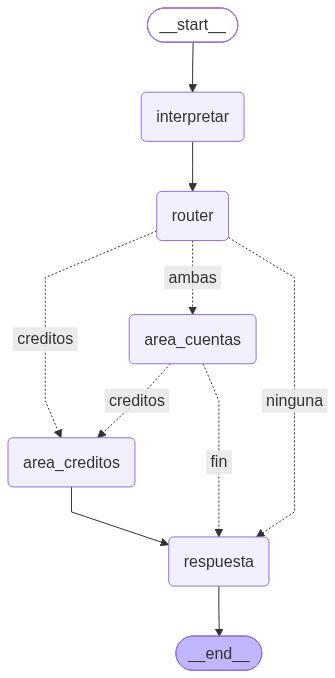

Supervisor


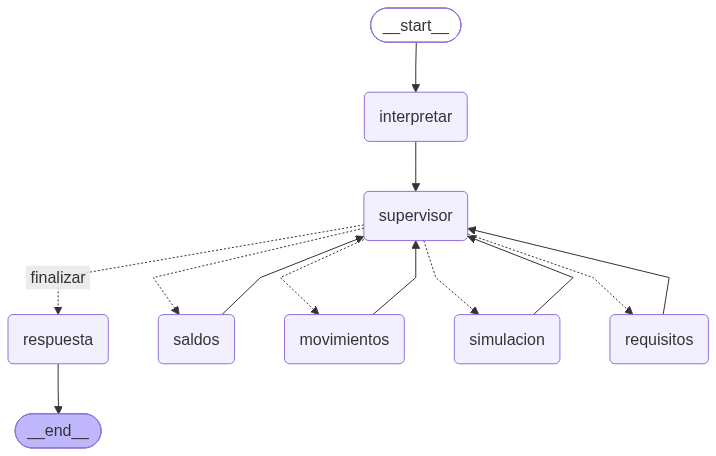

Jerárquica


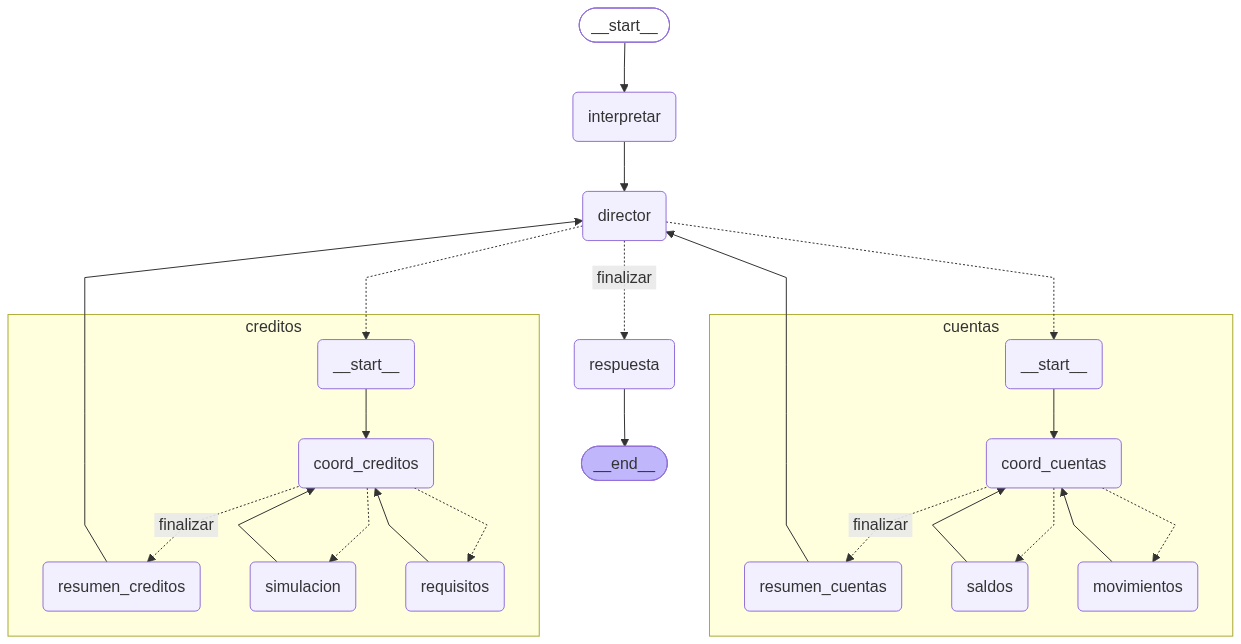

In [119]:
from IPython.display import display, Image

for a in ['Router', 'Supervisor', 'Jerárquica']:
    print(a)
    g = crear_grafo(a).get_graph(xray=True)      # xray=True: muestra también el interior de los subgrafos
    try:
        display(Image(g.draw_mermaid_png()))     # dibujo como imagen (usa un servicio web)
    except Exception:
        print(g.draw_mermaid())                  # si falla, texto Mermaid para pegar en mermaid.live

## Paso 12 · ▶️ Probar una solicitud sin interfaz
Ejecuta una solicitud y muestra la **bitácora**: quién le habló a quién. Cambia `ARQUITECTURA` y `SOLICITUD` para comparar.

In [110]:
import pandas as pd

# ── Cambia estas dos variables para comparar ──
ARQUITECTURA = 'Supervisor'      # 'Router' · 'Supervisor' · 'Jerárquica'
SOLICITUD = 'Consulta mis ahorros, simula financiar una moto y revisa capacidad y requisitos'

# Los montos (en Gradio vienen de los controles numéricos)
PARAMETROS = {'precio': 20_000_000, 'aporte': 5_000_000, 'meses': 36, 'ingreso': 3_500_000, 'obligaciones': 700_000}

# Estado inicial: el "expediente" vacío con la solicitud
inicial = {'solicitud': SOLICITUD, 'parametros': PARAMETROS, 'objetivos': [], 'resultados': {}, 'bitacora': [], 'decisiones': 0}

# invoke() ejecuta TODO el grafo y devuelve solo el estado final
# recursion_limit: máximo de pasos permitidos (otro freno anti-ciclos)
final = crear_grafo(ARQUITECTURA).invoke(inicial, config={'recursion_limit': 50})

# Mostramos la bitácora como tabla: quién le habló a quién
tabla = pd.DataFrame([{'paso': m['paso'],
                       'de':   NOMBRES.get(m['emisor'], m['emisor']),
                       'para': NOMBRES.get(m['destinatario'], m['destinatario']),
                       'mensaje': m['contenido']}
                      for m in final['bitacora']])
with pd.option_context('display.max_colwidth', 120):
    display(tabla)

print(final['respuesta'])

,paso,de,para,mensaje
0,1,Recepción,Coordinación,"Consulta mis ahorros, simula financiar una moto y revisa capacidad y requisitos"
1,2,Supervisor,Especialista de Saldos,Primero se debe consultar el saldo de ahorros antes de proceder con la simulación y la revisión de requisitos.
2,3,Especialista de Saldos,Supervisor,Saldo disponible: 5.000.000 COP. Fondos insuficientes para aprobar crédito según criterios habituales.
3,4,Supervisor,Especialista de Simulación,Se necesita simular el financiamiento de la moto para evaluar la capacidad de pago del cliente.
4,5,Especialista de Simulación,Supervisor,"Capital de 15 M COP, plazo 36 meses, cuota aproximada 498 215 COP; indica un préstamo con pagos mensuales de alreded..."
5,6,Supervisor,Especialista de Requisitos,Se han entregado los saldos y la simulación solicitada; ahora corresponde proporcionar los requisitos para la financ...
6,7,Especialista de Requisitos,Supervisor,"Solicitud ficticia con límite de cuota de 525,000 COP, incluye identificación y soporte de ingresos falsos; no se ap..."
7,8,Supervisor,Respuesta al cliente,Todas las consultas fueron atendidas y los resultados fueron entregados
8,9,Respuesta al cliente,Cliente,Respuesta final


Saldo ficticio: $5,000,000 COP.

Capital: $15,000,000 COP; cuota aproximada: $498,215 COP por 36 meses (tasa ficticia 1 %).

Límite ilustrativo de cuota: $525,000 COP. Documentos: Identificación ficticia, Soporte ficticio de ingresos.

El aporte declarado cabe en el saldo ficticio.

La cuota cabe en la comparación didáctica (no es una aprobación).

Datos ficticios. Sin movimientos de dinero reales.


## Paso 13 · ▶️ Construir la interfaz Gradio
El callback `atender` recorre el grafo con `stream(..., stream_mode='custom', subgraphs=True)` y, en cada aviso de inicio o fin, **redibuja** la interfaz con `yield`. Por eso en Jerárquica aparecen los coordinadores internos.

| Zona | Qué muestra |
|---|---|
| Tarjetas | Quién intervino; **azul** = trabajando ahora |
| Mensajes | Emisor → Destinatario: quién delega y quién recibe |
| Resultados | Los números de las herramientas |
| Respuesta | Texto final armado con esos números |

In [111]:
import gradio as gr


def tarjetas(bitacora, actual='', trabajando=False):
    """Genera el HTML de las tarjetas: una por cada participante que ha intervenido.
       La del nodo que está trabajando AHORA se pinta azul.
       Usamos colores fijos para que se lea igual en tema claro y oscuro."""
    # Participantes en orden de aparición, sin repetir (+ el que está trabajando ahora)
    nombres = list(dict.fromkeys([m['emisor'] for m in bitacora] + ([actual] if actual else [])))
    html = ''
    for n in nombres:
        activo = (n == actual and trabajando)
        html += (f'<div style="border:2px solid {"#2563eb" if activo else "#cbd5e1"};background:{"#dbeafe" if activo else "#f1f5f9"};'
                 f'padding:10px;border-radius:8px;color:#0f172a">'
                 f'<b style="color:#0f172a">{NOMBRES.get(n, n)}</b><br>'
                 f'<span style="color:#334155">{"Trabajando…" if activo else "Intervino"}</span></div>')
    return ('<div style="background:#ffffff;border-radius:12px;padding:12px;display:flex;gap:8px;flex-wrap:wrap">'
            + (html or '<span style="color:#64748b">Sin actividad</span>') + '</div>')


def atender(solicitud, arquitectura, precio, aporte, meses, ingreso, obligaciones):
    """Lo que pasa al hacer clic en 'Atender solicitud'.
       Es un GENERADOR: cada `yield` redibuja la interfaz, así vemos el avance en vivo."""

    # 1) Parámetros desde los controles numéricos (enteros)
    p = {'precio': int(precio), 'aporte': int(aporte), 'meses': int(meses),
         'ingreso': int(ingreso), 'obligaciones': int(obligaciones)}

    # 2) Estado inicial. Lo iremos actualizando con lo que devuelva cada nodo
    e = {'solicitud': solicitud, 'parametros': p, 'objetivos': [], 'resultados': {}, 'bitacora': [], 'decisiones': 0}

    def vista(actual='', trabajando=False, estado=''):
        # Devuelve los 5 valores de salida en el MISMO orden que los outputs del botón:
        # [actividad, mensajes, resultados, salida, estado]
        filas = [[m['paso'], NOMBRES.get(m['emisor'], m['emisor']),
                  NOMBRES.get(m['destinatario'], m['destinatario']), m['contenido']] for m in e['bitacora']]
        return tarjetas(e['bitacora'], actual, trabajando), filas, e['resultados'], e.get('respuesta', ''), estado

    yield vista(estado='Iniciando ' + arquitectura + '…')       # primer dibujo: vacío

    try:
        grafo = crear_grafo(arquitectura)
        # stream(): ejecuta el grafo y nos entrega cada aviso del "megáfono" (get_stream_writer)
        #   stream_mode='custom' → solo los avisos de observable()
        #   subgraphs=True       → incluye avisos de nodos dentro de subgrafos (coordinadores)
        for _, aviso in grafo.stream(e, stream_mode='custom', subgraphs=True, config={'recursion_limit': 50}):
            if aviso['tipo'] == 'fin':
                e.update(aviso['salida'])                # guardamos lo que devolvió el nodo
            # Redibujamos: si es 'inicio', la tarjeta de ese nodo se pinta azul
            yield vista(aviso['nodo'], aviso['tipo'] == 'inicio', NOMBRES.get(aviso['nodo'], aviso['nodo']))
    except Exception as error:
        # Cualquier error (contrato inválido, opción no permitida, límite...) detiene la solicitud
        yield vista(estado=f'⛔ Detenido: {error}')
        return

    yield vista(estado=f'✅ {arquitectura}: terminado')


# ═══════════════════════════════════════════════════════════════════
# La interfaz: los componentes se dibujan en el orden en que se crean
# ═══════════════════════════════════════════════════════════════════
with gr.Blocks(title='Sucursal bancaria multiagente') as demo:
    gr.Markdown('# 🏦 La sucursal bancaria multiagente\nMismos datos y herramientas; cambia **quién decide**. Todo es ficticio.')

    # --- Entradas ---
    arquitectura = gr.Radio(['Router', 'Supervisor', 'Jerárquica'], value='Router', label='Arquitectura')
    solicitud = gr.Textbox(value='¿Cuánto saldo tengo disponible?', label='Solicitud del cliente')
    gr.Examples([['¿Cuánto saldo tengo disponible?'], ['Muéstrame mis movimientos'],
                 ['Quiero simular una cuota para financiar una moto'],
                 ['Consulta mis ahorros, simula financiar una moto y revisa capacidad y requisitos'],
                 ['Quiero abrir un seguro de viaje']], inputs=solicitud)   # clic en un ejemplo = lo copia en la caja
    with gr.Row():      # los controles numéricos en una fila
        precio = gr.Number(20_000_000, precision=0, label='Precio COP')
        aporte = gr.Number(5_000_000, precision=0, label='Aporte declarado COP')
        meses = gr.Number(36, precision=0, label='Meses')
        ingreso = gr.Number(3_500_000, precision=0, label='Ingreso COP')
        obligaciones = gr.Number(700_000, precision=0, label='Obligaciones COP')
    boton = gr.Button('Atender solicitud', variant='primary')

    # --- Salidas ---
    estado = gr.Markdown('Lista para comenzar')                 # línea de estado
    actividad = gr.HTML()                                       # tarjetas
    mensajes = gr.Dataframe(headers=['Paso', 'Emisor', 'Destinatario', 'Mensaje'], wrap=True,
                            interactive=False, label='Mensajes entre participantes')
    with gr.Row():
        resultados = gr.JSON(label='Resultados de herramientas')
        salida = gr.Textbox(label='Respuesta al cliente', lines=10)

    # --- Conexión: al hacer clic, se llama a atender(entradas) y se actualizan las salidas ---
    boton.click(atender,
                [solicitud, arquitectura, precio, aporte, meses, ingreso, obligaciones],   # entradas (en orden)
                [actividad, mensajes, resultados, salida, estado])                          # salidas (mismo orden que vista())

print('Interfaz construida. Ejecuta el paso 14 para abrirla.')

Interfaz construida. Ejecuta el paso 14 para abrirla.


## Paso 14 · ▶️ Abrir la interfaz
En Colab, `share=True` crea un enlace público temporal (solo datos ficticios). En local no se comparte: la interfaz se abre en `http://127.0.0.1:7860` (o el siguiente puerto libre) y solo es accesible desde tu equipo, así nadie más puede usar tu clave de Groq a través del enlace. `debug=False` deja la celda libre para seguir usando el notebook.

In [118]:
# ¿Estamos en Colab? (el módulo google.colab solo existe allí)
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# share=EN_COLAB → en Colab crea además un enlace público temporal (solo datos ficticios);
#                  en tu PC la interfaz solo se abre en tu equipo (http://127.0.0.1:7860)
# debug=False    → la celda termina y puedes seguir ejecutando otras celdas
demo.launch(share=EN_COLAB, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fc99d0ed06c2ba55c9.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Paso 15 · ▶️ Cerrar la interfaz
Ejecútala al terminar, o antes de reconstruir la interfaz (paso 13) si cambiaste código.

In [113]:
# Apaga el servidor de Gradio (libera el puerto y el enlace público)
demo.close()

Closing server running on port: 7862


## Paso 16 · Recorrido guiado y ejercicio

### Recorrido guiado (en la interfaz)
| # | Arquitectura y solicitud | Qué observar |
|---|---|---|
| 1 | **Router** · «¿Cuánto saldo tengo disponible?» | Una clasificación inicial y la intervención de Saldos |
| 2 | **Supervisor** · misma solicitud | Saldos **devuelve** el control al Supervisor, que decide finalizar |
| 3 | **Jerárquica** · misma solicitud | Director → Coordinador de Cuentas → Saldos → Coordinador → Resumen → Director. Más pasos, **mismo saldo** |
| 4 | Las tres · consulta mixta (ahorros + moto + requisitos) | Compara rutas sin cambiar controles |
| 5 | Resultados | Capital $15.000.000, cuota **$498.215**, límite **$525.000** |
| 6 | Cualquiera · «Quiero abrir un seguro de viaje» | Pide reformular; **no** inventa un equipo nuevo |

> 🤖 Como decide un LLM, **el orden** de los especialistas puede variar entre ejecuciones. **Los números no cambian**: los calcula Python.

### Ejercicio de clase
Sigue **`05_Ejercicio_Sucursal_Bancaria.docx`**: predice, ejecuta, registra la traza de una consulta mixta, prueba el aporte de $6.000.000 y escribe un ADR breve.

### ⚠️ Errores frecuentes
| Síntoma | Causa | Qué hacer |
|---|---|---|
| `GROQ_API_KEY` vacía / error 401 | No está en `.env` (local) o en Secrets, o falta dar acceso al notebook | Local: agrégala a `.env` · Colab: 🔑 Secrets → agregar `GROQ_API_KEY` y activar el acceso |
| La interfaz no se ve dentro de VS Code | El visor del notebook no muestra la vista incrustada | Abre en el navegador la URL local que imprime el paso 14 (`http://127.0.0.1:7860`) |
| Error 429 (rate limit) | Muchas llamadas seguidas | Espera unos segundos y repite |
| `ValidationError` de Pydantic | El LLM devolvió un JSON que no cumple el contrato | Vuelve a intentar; es el contrato funcionando |
| Cambié el monto en la frase y no cambió la cuota | Los importes vienen de los **controles** | Cambia los campos numéricos |
| La interfaz no refleja cambios de código | Sigue abierta la versión anterior | Paso 15 → re-ejecutar → 13 → 14 |

## Fuentes (consultadas el 22-10-2026)
- [LangChain: Router](https://docs.langchain.com/oss/python/langchain/multi-agent/router) · [Subagents](https://docs.langchain.com/oss/python/langchain/multi-agent/subagents)
- [LangGraph: Use subgraphs](https://docs.langchain.com/oss/python/langgraph/use-subgraphs) · [Streaming](https://docs.langchain.com/oss/python/langgraph/streaming)
- [Gradio: Streaming outputs](https://www.gradio.app/guides/streaming-outputs)

# 📎 Anexo · Las tres arquitecturas escritas "a mano"
Arriba usamos funciones que **fabrican** nodos y grafos (`especialista()`, `crear_subgrafo()`, `crear_grafo()`), ciclos `for` y `observable`. Eso es cómodo, pero esconde la estructura.

Aquí construimos **cada arquitectura desde cero**, con:
- ✅ **una función por nodo** (sin fábricas),
- ✅ **cada `add_node` y `add_edge` escrito explícitamente** (sin ciclos),
- ✅ `print` dentro de cada nodo para ver el recorrido en la salida,
- ❌ sin `observable` ni Gradio.

Los nombres terminan en `_simple` para **no pisar** las funciones de arriba (así Gradio sigue funcionando).

Reutilizamos solo lo que **no es arquitectura**: los datos, `herramienta()` (Python), `pedir_json()` (Groq) y los contratos `Objetivos` y `Seleccion`.

| Paso | Qué haces |
|---|---|
| A.1 | Estado y piezas comunes: Recepción, 4 especialistas y Respuesta |
| A.2 | **Router** |
| A.3 | **Supervisor** |
| A.4 | **Jerárquica** (con dos subgrafos) |

## A.1 · ▶️ Estado y piezas comunes
**Receta para construir cualquier grafo en LangGraph:**
1. Definir el **estado** (qué datos viajan).
2. Escribir los **nodos** (funciones que reciben el estado y devuelven lo que cambia).
3. Crear el grafo, **agregar nodos** y **conectar aristas**.
4. **Compilar** y **ejecutar**.

Estos nodos son iguales en las tres arquitecturas.

In [114]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# ── 1) EL ESTADO: lo mínimo que necesitamos ─────────────────────────
class EstadoSimple(TypedDict):
    solicitud: str        # lo que escribió el cliente
    parametros: dict      # montos (precio, aporte, meses, ingreso, obligaciones)
    objetivos: list       # tareas que detecta Recepción
    resultados: dict      # lo que devuelven los especialistas
    siguiente: str        # a quién llamar después (lo decide un coordinador)
    ruta: str             # decisión del Router


# ── 2) NODOS COMUNES ───────────────────────────────────────────────
def recepcion(e):
    # El LLM detecta qué pidió el cliente (contrato Objetivos)
    o = pedir_json('Eres Recepción de un banco ficticio. Identifica qué pidió el cliente: '
                   'saldo o ahorros -> saldos; movimientos -> movimientos; '
                   'financiar o cuota -> simulacion; requisitos o capacidad -> requisitos. '
                   'Si no pide nada de eso, lista vacía.',
                   {'solicitud': e['solicitud']}, Objetivos)
    print('📥 Recepción detectó:', o.tareas)
    return {'objetivos': o.tareas}


# Un nodo por especialista. Cada uno: llama a su herramienta y AGREGA su resultado.
def saldos(e):
    print('   💰 Saldos trabaja')
    nuevo = herramienta('saldos', e['parametros'])
    return {'resultados': {**e['resultados'], 'saldos': nuevo}}

def movimientos(e):
    print('   📄 Movimientos trabaja')
    nuevo = herramienta('movimientos', e['parametros'])
    return {'resultados': {**e['resultados'], 'movimientos': nuevo}}

def simulacion(e):
    print('   🧮 Simulación trabaja')
    nuevo = herramienta('simulacion', e['parametros'])
    return {'resultados': {**e['resultados'], 'simulacion': nuevo}}

def requisitos(e):
    print('   📋 Requisitos trabaja')
    nuevo = herramienta('requisitos', e['parametros'])
    return {'resultados': {**e['resultados'], 'requisitos': nuevo}}


def respuesta_final(e):
    print('📤 Respuesta con:', list(e['resultados']))
    return {}      # no cambia nada: solo marca el final


# Datos de entrada que usaremos en las tres pruebas
ENTRADA = {
    'solicitud': 'Consulta mis ahorros, simula financiar una moto y revisa capacidad y requisitos',
    'parametros': {'precio': 20_000_000, 'aporte': 5_000_000, 'meses': 36, 'ingreso': 3_500_000, 'obligaciones': 700_000},
    'objetivos': [], 'resultados': {}, 'siguiente': '', 'ruta': '',
}
print('Piezas comunes listas.')

Piezas comunes listas.


## A.2 · ▶️ Router: decide UNA vez
```
START → recepcion → router ─┬─ cuentas  → area_cuentas ──────────────► respuesta → END
                            ├─ creditos → area_creditos ─────────────► respuesta
                            ├─ ambas    → area_cuentas → area_creditos ► respuesta
                            └─ ninguna  ────────────────────────────► respuesta
```
- `router` **no usa LLM**: mira los objetivos y escribe `ruta`.
- Cada **área** ejecuta en orden a sus especialistas pedidos. **Nadie revisa** entre uno y otro.

In [115]:
# ── NODOS PROPIOS DEL ROUTER ───────────────────────────────────────
def router_simple(e):
    pide_cuentas  = 'saldos' in e['objetivos'] or 'movimientos' in e['objetivos']
    pide_creditos = 'simulacion' in e['objetivos'] or 'requisitos' in e['objetivos']
    if pide_cuentas and pide_creditos: ruta = 'ambas'
    elif pide_cuentas:                 ruta = 'cuentas'
    elif pide_creditos:                ruta = 'creditos'
    else:                              ruta = 'ninguna'
    print('🔀 Router decide (una sola vez):', ruta)
    return {'ruta': ruta}

def area_cuentas(e):
    print('🏢 Área de Cuentas')
    r = dict(e['resultados'])
    if 'saldos' in e['objetivos']:      r['saldos'] = saldos(e)['resultados']['saldos']
    if 'movimientos' in e['objetivos']: r['movimientos'] = movimientos(e)['resultados']['movimientos']
    return {'resultados': r}

def area_creditos(e):
    print('🏢 Área de Créditos')
    r = dict(e['resultados'])
    if 'simulacion' in e['objetivos']: r['simulacion'] = simulacion(e)['resultados']['simulacion']
    if 'requisitos' in e['objetivos']: r['requisitos'] = requisitos(e)['resultados']['requisitos']
    return {'resultados': r}

# Funciones que LEEN el estado para que el grafo sepa qué camino tomar
def leer_ruta(e):
    return e['ruta']

def despues_de_cuentas(e):
    return 'area_creditos' if e['ruta'] == 'ambas' else 'respuesta'


# ── 3) ARMAR EL GRAFO ──────────────────────────────────────────────
g = StateGraph(EstadoSimple)

# 3a) Agregar nodos
g.add_node('recepcion', recepcion)
g.add_node('router', router_simple)
g.add_node('area_cuentas', area_cuentas)
g.add_node('area_creditos', area_creditos)
g.add_node('respuesta', respuesta_final)

# 3b) Conectar aristas fijas
g.add_edge(START, 'recepcion')
g.add_edge('recepcion', 'router')
g.add_edge('area_creditos', 'respuesta')
g.add_edge('respuesta', END)

# 3c) Aristas condicionales: según lo que devuelva la función, a qué nodo ir
g.add_conditional_edges('router', leer_ruta, {
    'cuentas':  'area_cuentas',
    'creditos': 'area_creditos',
    'ambas':    'area_cuentas',
    'ninguna':  'respuesta',
})
g.add_conditional_edges('area_cuentas', despues_de_cuentas, {
    'area_creditos': 'area_creditos',
    'respuesta':     'respuesta',
})

# ── 4) COMPILAR Y EJECUTAR ─────────────────────────────────────────
grafo_router = g.compile()
final = grafo_router.invoke(ENTRADA)
print('\nResultados:', final['resultados'])

📥 Recepción detectó: ['saldos', 'simulacion', 'requisitos']
🔀 Router decide (una sola vez): ambas
🏢 Área de Cuentas
   💰 Saldos trabaja
🏢 Área de Créditos
   🧮 Simulación trabaja
   📋 Requisitos trabaja
📤 Respuesta con: ['saldos', 'simulacion', 'requisitos']

Resultados: {'saldos': {'saldo_cop': 5000000}, 'simulacion': {'capital_cop': 15000000, 'meses': 36, 'cuota_aproximada_cop': 498215}, 'requisitos': {'limite_cuota_ilustrativo_cop': 525000, 'documentos': ['Identificación ficticia', 'Soporte ficticio de ingresos']}}


**🤔 Observa:** el Router aparece **una sola vez** en la salida. Después, las áreas trabajan sin que nadie revise.

## A.3 · ▶️ Supervisor: decide después de CADA resultado
```
START → recepcion → supervisor ─┬─► saldos ──────┐
                       ▲        ├─► movimientos ─┤
                       │        ├─► simulacion ──┤   (todos VUELVEN al supervisor)
                       │        ├─► requisitos ──┘
                       └────────┘
                                └─ finalizar → respuesta → END
```
La clave son las **4 aristas de retorno**: `add_edge('saldos', 'supervisor')`, etc.

In [116]:
# ── NODO PROPIO DEL SUPERVISOR ─────────────────────────────────────
def supervisor_simple(e):
    # 1) ¿Qué tareas pedidas aún no tienen resultado?
    pendientes = [t for t in e['objetivos'] if t not in e['resultados']]
    opciones = pendientes if pendientes else ['finalizar']

    # 2) El LLM elige UNA opción (contrato Seleccion)
    d = pedir_json('Eres el Supervisor. Elige exactamente UNA opción de "opciones".',
                   {'solicitud': e['solicitud'], 'resultados_recibidos': list(e['resultados']),
                    'opciones': opciones}, Seleccion)

    # 3) Control: no puede elegir algo fuera de la lista
    if d.siguiente not in opciones:
        raise ValueError('Opción no permitida: ' + d.siguiente)

    print('🧑‍💼 Supervisor ve', list(e['resultados']), '→ elige', d.siguiente)
    return {'siguiente': d.siguiente}

def leer_siguiente(e):
    return e['siguiente']


# ── ARMAR EL GRAFO ─────────────────────────────────────────────────
g = StateGraph(EstadoSimple)

# Nodos
g.add_node('recepcion', recepcion)
g.add_node('supervisor', supervisor_simple)
g.add_node('saldos', saldos)
g.add_node('movimientos', movimientos)
g.add_node('simulacion', simulacion)
g.add_node('requisitos', requisitos)
g.add_node('respuesta', respuesta_final)

# Aristas fijas
g.add_edge(START, 'recepcion')
g.add_edge('recepcion', 'supervisor')
g.add_edge('respuesta', END)

# ⭐ Aristas de RETORNO: cada especialista vuelve al supervisor
g.add_edge('saldos', 'supervisor')
g.add_edge('movimientos', 'supervisor')
g.add_edge('simulacion', 'supervisor')
g.add_edge('requisitos', 'supervisor')

# Arista condicional: el supervisor decide a dónde ir
g.add_conditional_edges('supervisor', leer_siguiente, {
    'saldos':      'saldos',
    'movimientos': 'movimientos',
    'simulacion':  'simulacion',
    'requisitos':  'requisitos',
    'finalizar':   'respuesta',
})

# ── COMPILAR Y EJECUTAR ────────────────────────────────────────────
grafo_supervisor = g.compile()
final = grafo_supervisor.invoke(ENTRADA, config={'recursion_limit': 25})   # freno anti-ciclos
print('\nResultados:', final['resultados'])

📥 Recepción detectó: ['saldos', 'simulacion', 'requisitos']
🧑‍💼 Supervisor ve [] → elige simulacion
   🧮 Simulación trabaja
🧑‍💼 Supervisor ve ['simulacion'] → elige requisitos
   📋 Requisitos trabaja
🧑‍💼 Supervisor ve ['simulacion', 'requisitos'] → elige saldos
   💰 Saldos trabaja
🧑‍💼 Supervisor ve ['simulacion', 'requisitos', 'saldos'] → elige finalizar
📤 Respuesta con: ['simulacion', 'requisitos', 'saldos']

Resultados: {'simulacion': {'capital_cop': 15000000, 'meses': 36, 'cuota_aproximada_cop': 498215}, 'requisitos': {'limite_cuota_ilustrativo_cop': 525000, 'documentos': ['Identificación ficticia', 'Soporte ficticio de ingresos']}, 'saldos': {'saldo_cop': 5000000}}


**🤔 Observa:** el Supervisor aparece **antes y después de cada especialista**. Con 3 tareas toma **4 decisiones**: la última es `finalizar`.

## A.4 · ▶️ Jerárquica: Director → Equipos (subgrafos)
Primero construimos **dos grafos pequeños** (un equipo por área) y después los usamos como **nodos** del grafo del Director.
```
Subgrafo «cuentas»:   START → coord_cuentas ⇄ saldos / movimientos ;  finalizar → END
Subgrafo «créditos»:  START → coord_creditos ⇄ simulacion / requisitos ;  finalizar → END

Grafo principal:  START → recepcion → director ⇄ equipo_cuentas / equipo_creditos
                                         └─ finalizar → respuesta → END
```

In [117]:
# ════════════════════════════════════════════════════════════════════
# PARTE 1: Subgrafo del EQUIPO DE CUENTAS
# ════════════════════════════════════════════════════════════════════
def coord_cuentas(e):
    # Solo conoce SUS especialistas: saldos y movimientos
    pendientes = [t for t in ['saldos', 'movimientos'] if t in e['objetivos'] and t not in e['resultados']]
    opciones = pendientes if pendientes else ['finalizar']
    d = pedir_json('Eres el Coordinador de Cuentas. Elige UNA opción de "opciones".',
                   {'solicitud': e['solicitud'], 'resultados_recibidos': list(e['resultados']),
                    'opciones': opciones}, Seleccion)
    if d.siguiente not in opciones:
        raise ValueError('Opción no permitida: ' + d.siguiente)
    print('   👤 Coord. Cuentas → elige', d.siguiente)
    return {'siguiente': d.siguiente}

sub = StateGraph(EstadoSimple)
sub.add_node('coord_cuentas', coord_cuentas)
sub.add_node('saldos', saldos)
sub.add_node('movimientos', movimientos)
sub.add_edge(START, 'coord_cuentas')
sub.add_edge('saldos', 'coord_cuentas')          # vuelve a SU coordinador
sub.add_edge('movimientos', 'coord_cuentas')
sub.add_conditional_edges('coord_cuentas', leer_siguiente, {
    'saldos': 'saldos', 'movimientos': 'movimientos', 'finalizar': END,   # END = sale del subgrafo
})
equipo_cuentas = sub.compile()


# ════════════════════════════════════════════════════════════════════
# PARTE 2: Subgrafo del EQUIPO DE CRÉDITOS (misma forma)
# ════════════════════════════════════════════════════════════════════
def coord_creditos(e):
    pendientes = [t for t in ['simulacion', 'requisitos'] if t in e['objetivos'] and t not in e['resultados']]
    opciones = pendientes if pendientes else ['finalizar']
    d = pedir_json('Eres el Coordinador de Créditos. Elige UNA opción de "opciones".',
                   {'solicitud': e['solicitud'], 'resultados_recibidos': list(e['resultados']),
                    'opciones': opciones}, Seleccion)
    if d.siguiente not in opciones:
        raise ValueError('Opción no permitida: ' + d.siguiente)
    print('   👤 Coord. Créditos → elige', d.siguiente)
    return {'siguiente': d.siguiente}

sub = StateGraph(EstadoSimple)
sub.add_node('coord_creditos', coord_creditos)
sub.add_node('simulacion', simulacion)
sub.add_node('requisitos', requisitos)
sub.add_edge(START, 'coord_creditos')
sub.add_edge('simulacion', 'coord_creditos')
sub.add_edge('requisitos', 'coord_creditos')
sub.add_conditional_edges('coord_creditos', leer_siguiente, {
    'simulacion': 'simulacion', 'requisitos': 'requisitos', 'finalizar': END,
})
equipo_creditos = sub.compile()


# ════════════════════════════════════════════════════════════════════
# PARTE 3: El DIRECTOR y el grafo principal
# ════════════════════════════════════════════════════════════════════
def director_simple(e):
    # Solo conoce ÁREAS, no especialistas
    opciones = []
    if any(t in e['objetivos'] and t not in e['resultados'] for t in ['saldos', 'movimientos']):
        opciones.append('equipo_cuentas')
    if any(t in e['objetivos'] and t not in e['resultados'] for t in ['simulacion', 'requisitos']):
        opciones.append('equipo_creditos')
    if not opciones:
        opciones = ['finalizar']
    d = pedir_json('Eres el Director. Delega en UNA opción de "opciones".',
                   {'solicitud': e['solicitud'], 'resultados_recibidos': list(e['resultados']),
                    'opciones': opciones}, Seleccion)
    if d.siguiente not in opciones:
        raise ValueError('Opción no permitida: ' + d.siguiente)
    print('🎩 Director ve', list(e['resultados']), '→ delega en', d.siguiente)
    return {'siguiente': d.siguiente}

g = StateGraph(EstadoSimple)
g.add_node('recepcion', recepcion)
g.add_node('director', director_simple)
g.add_node('equipo_cuentas', equipo_cuentas)     # ⭐ un subgrafo compilado se agrega como un nodo
g.add_node('equipo_creditos', equipo_creditos)
g.add_node('respuesta', respuesta_final)

g.add_edge(START, 'recepcion')
g.add_edge('recepcion', 'director')

g.add_edge('equipo_cuentas', 'director')         # el equipo devuelve al Director
g.add_edge('equipo_creditos', 'director')

g.add_edge('respuesta', END)
g.add_conditional_edges('director', leer_siguiente, {
    'equipo_cuentas':  'equipo_cuentas',
    'equipo_creditos': 'equipo_creditos',
    'finalizar':       'respuesta',
})

grafo_jerarquico = g.compile()
final = grafo_jerarquico.invoke(ENTRADA, config={'recursion_limit': 25})
print('\nResultados:', final['resultados'])

📥 Recepción detectó: ['saldos', 'simulacion', 'requisitos']
🎩 Director ve [] → delega en equipo_creditos
   👤 Coord. Créditos → elige simulacion
   🧮 Simulación trabaja
   👤 Coord. Créditos → elige requisitos
   📋 Requisitos trabaja
   👤 Coord. Créditos → elige finalizar
🎩 Director ve ['simulacion', 'requisitos'] → delega en equipo_cuentas
   👤 Coord. Cuentas → elige saldos
   💰 Saldos trabaja
   👤 Coord. Cuentas → elige finalizar
🎩 Director ve ['simulacion', 'requisitos', 'saldos'] → delega en finalizar
📤 Respuesta con: ['simulacion', 'requisitos', 'saldos']

Resultados: {'simulacion': {'capital_cop': 15000000, 'meses': 36, 'cuota_aproximada_cop': 498215}, 'requisitos': {'limite_cuota_ilustrativo_cop': 525000, 'documentos': ['Identificación ficticia', 'Soporte ficticio de ingresos']}, 'saldos': {'saldo_cop': 5000000}}


**🤔 Observa:** hay **dos niveles** de decisión. El Director solo dice "equipo de cuentas" o "equipo de créditos"; dentro de cada equipo, el Coordinador elige al especialista.

### Comparación final
| | Router | Supervisor | Jerárquica |
|---|---|---|---|
| Nodo que decide | `router` (sin LLM) | `supervisor` | `director` + `coord_cuentas` + `coord_creditos` |
| Aristas que lo definen | `add_conditional_edges('router', ...)` y **ninguna de retorno** | `add_edge('saldos', 'supervisor')` ×4 (**retorno**) | `add_node('equipo_cuentas', subgrafo)` + `add_edge('equipo_cuentas', 'director')` |
| ¿Cuántas veces decide? (consulta mixta) | 1 | 4 | 3 del Director + 5 de los coordinadores |

> 💡 **Reto:** compara este anexo con `crear_grafo()` (paso 10). Es el mismo grafo: allá usamos ciclos `for` y fábricas para no repetir líneas.